# Contextual politeness feature extraction

## Phase 1 computational pilot

The previous CMV experiments measured explicit courtesy through ConvoKit. This pilot runs the frozen [Intel Polite Guard checkpoint](https://huggingface.co/Intel/polite-guard/tree/2294eaff6b7ba7c238148b6bcea548d9b63ab4df) on 100 distinct opening replies from the archived matched training pairs. The seed is 42, with 25 openings sampled per word-count quartile. The aim is to verify the extraction and measure computational cost.

The model outputs probabilities for impolite, neutral, somewhat polite, and polite. The engineered ordinal score uses weights 0, 1, 2, and 3 in that order. The extractor averages probabilities by the number of content tokens per chunk and also records the highest chunk-level impoliteness probability. The score is a model-based proxy for politeness. Human agreement will be evaluated separately.

Tokenization happens once per argument. Fixed and randomized boundaries slice those token IDs directly, and special tokens are added to each chunk before dynamic batch padding. Randomized segmentation retains token order and chunk count, with boundaries seeded separately per argument. Exact token-ID sequences share predictions within the run.

[Reusable classifier](politeness_extractor.py) · [Pilot runner](run_pilot.py)

### Pilot outputs and checks

The runner saves the argument and chunk Parquet files and a JSON manifest under the project's processed-data directory. It checks contiguous, complete token coverage, normalized probabilities, and exact repeatability of the seeded segmentation. The same classifier also completed a full-size input check with the project's CardiffNLP sentiment checkpoint.

The timings below are from consecutive configurations sharing a cache. The first configuration starts cold, and later rows reuse predictions from prior rows. Per-chunk inference time is the batch time divided across newly evaluated chunks, with reused predictions charged zero.

In [1]:
import json
from pathlib import Path

import pandas as pd

project = next(
    candidate / "project"
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "pyproject.toml").is_file() and (candidate / "team-setup").is_dir()
)
results = project / "data/processed/linguistic-features/politeness-experiment/phase-1"
run = sorted(results.glob("*/experiment_metadata.json"))[-1].parent
metadata = json.loads((run / "experiment_metadata.json").read_text())
arguments = pd.read_parquet(run / "argument_predictions.parquet")
chunks = pd.read_parquet(run / "chunk_predictions.parquet")
assert metadata["phase"] == 1 and metadata["split"] == "train"
assert arguments.groupby("segmentation")["argument_id"].nunique().eq(metadata["arguments"]).all()
assert len(chunks) == sum(row["chunks"] for row in metadata["configurations"])

print(pd.DataFrame(metadata["configurations"]).to_string(index=False))
print(f"\n{len(arguments)} argument predictions and {len(chunks)} chunk predictions")
print(f"{metadata['changed_boundaries']} openings changed boundaries under the seeded trial.")
print(f"Replay retrieved all {metadata['repeat_cache_hits']} chunks from cache.")
print(f"CPU wall time before export: {metadata['wall_seconds_before_export']:.2f} s")


 segmentation  chunks  new_predictions  cache_hits  seconds
    128_fixed     269              269           0    7.630
    256_fixed     159              110          49    6.253
    510_fixed     114               54          60    5.751
128_random_42     269              247          22    6.657

400 argument predictions and 811 chunk predictions
78 openings changed boundaries under the seeded trial.
Replay retrieved all 269 chunks from cache.
CPU wall time before export: 28.52 s


### Rerun the pilot

From the project root, run the following commands in the project environment. The first command downloads the pinned checkpoint into the default local directory. The second reads the archived training openings and writes a new timestamped run.

```sh
python -c 'from huggingface_hub import snapshot_download; snapshot_download("Intel/polite-guard", revision="2294eaff6b7ba7c238148b6bcea548d9b63ab4df", local_dir="project/data/processed/linguistic-features/polite-guard-checkpoint", allow_patterns=["config.json", "tokenizer.json", "tokenizer_config.json", "special_tokens_map.json", "vocab.txt", "model.safetensors"])'
python project/notebooks/linguistic-features/politeness_experiment/run_pilot.py
```

## Phase 2 chunk-size sensitivity

The same frozen model scored every distinct archived matched-training opening with fixed boundaries at 128, 256, and 510 content tokens. The input token IDs and weighting rule are constant. For openings of at most 510 tokens, the 510-token configuration is the unchunked reference. Openings longer than 510 tokens have three segmented predictions.

**Agreement metrics.** Spearman correlation measures agreement in the ranking of the ordinal scores. Mean absolute difference is in score points on the 0–3 scale. Class agreement uses the class with the highest aggregated probability. A negative signed difference means that the smaller chunks gave a lower score on average.

**Comparison groups.** The full-sample rows include short openings with identical token inputs. The different-segmentation rows retain openings longer than the smaller limit. The unchunked-reference rows restrict the sample to openings of at most 510 tokens, and show results with and without unchanged inputs.

[Scoring runner](run_chunk_size_experiment.py) · [Analysis and plotting](analyze_chunk_sizes.py)

In [2]:
phase2_run_id = "20261124T045848489197Z"
phase2_run = project / "data/processed/linguistic-features/politeness-experiment/phase-2" / phase2_run_id
phase2_analysis = phase2_run / "analysis"
phase2_metadata = json.loads((phase2_run / "experiment_metadata.json").read_text())
agreement = pd.read_csv(phase2_analysis / "agreement.csv")
subgroups = pd.read_csv(phase2_analysis / "subgroup_agreement.csv")
assert phase2_metadata["phase"] == 2 and phase2_metadata["split"] == "train"

print(agreement.round(4).to_string(index=False))
print()
print(pd.DataFrame(phase2_metadata["configurations"]).to_string(index=False))
print("Total wall time before export (minutes)", round(phase2_metadata["wall_seconds_before_export"] / 60, 2))


 smaller_tokens  larger_tokens                                     cohort  n_openings  spearman  mean_absolute_difference  mean_signed_difference  class_agreement
            128            256                                        all        6581    0.9193                    0.1550                  0.0850           0.9573
            128            256                     different_segmentation        5007    0.8981                    0.2037                  0.1117           0.9439
            128            510                                        all        6581    0.9002                    0.1993                  0.0507           0.9400
            128            510                     different_segmentation        5007    0.8756                    0.2620                  0.0666           0.9211
            128            510                        unchunked_reference        5727    0.8988                    0.1815                  0.0639           0.9471
            128       

### Sensitivity by length, topic, and outcome

Length bands use content-token counts and follow the three chunk limits. Topic and outcome use the archived matched-pair labels, with each opening counted once. The within-band results are descriptive. A topic or outcome group can still have a different length distribution within a band. The subgroup CSV includes all three chunk-size comparisons, with sample sizes.

In [3]:
extremes = subgroups.loc[subgroups["smaller_tokens"].eq(128) & subgroups["larger_tokens"].eq(510)]
columns = ["n_openings", "mean_absolute_difference", "spearman", "class_agreement"]
print("128 vs. 510 content tokens by opening length")
print(extremes.loc[extremes["dimension"].eq("length"), ["length_group", *columns]].round(4).to_string(index=False))
print("\n128 vs. 510 content tokens by draft topic and opening length")
print(extremes.loc[extremes["dimension"].eq("topic_within_length"), ["broad_topic", "length_group", *columns]]
      .pivot(index="broad_topic", columns="length_group", values="mean_absolute_difference")
      .reindex(columns=["≤128", "129–256", "257–510", ">510"]).round(3).to_string())
print("\n128 vs. 510 content tokens by archived outcome and opening length")
print(extremes.loc[extremes["dimension"].eq("outcome_within_length"), ["outcome", "length_group", *columns]]
      .round(4).to_string(index=False))


128 vs. 510 content tokens by opening length
length_group  n_openings  mean_absolute_difference  spearman  class_agreement
        ≤128        1574                    0.0000    1.0000           1.0000
     129–256        2296                    0.1970    0.8884           0.9469
     257–510        1857                    0.3162    0.8387           0.9025
        >510         854                    0.3189    0.8670           0.8923

128 vs. 510 content tokens by draft topic and opening length
length_group                    ≤128  129–256  257–510   >510
broad_topic                                                  
Education, work & economics      0.0    0.188    0.360  0.351
Ethics & religion                0.0    0.174    0.259  0.276
Health & reproduction            0.0    0.175    0.261  0.386
Identity & relationships         0.0    0.196    0.270  0.266
Media, leisure & everyday life   0.0    0.218    0.349  0.358
Other / unclear                  0.0    0.183    0.345  0.276
Politic

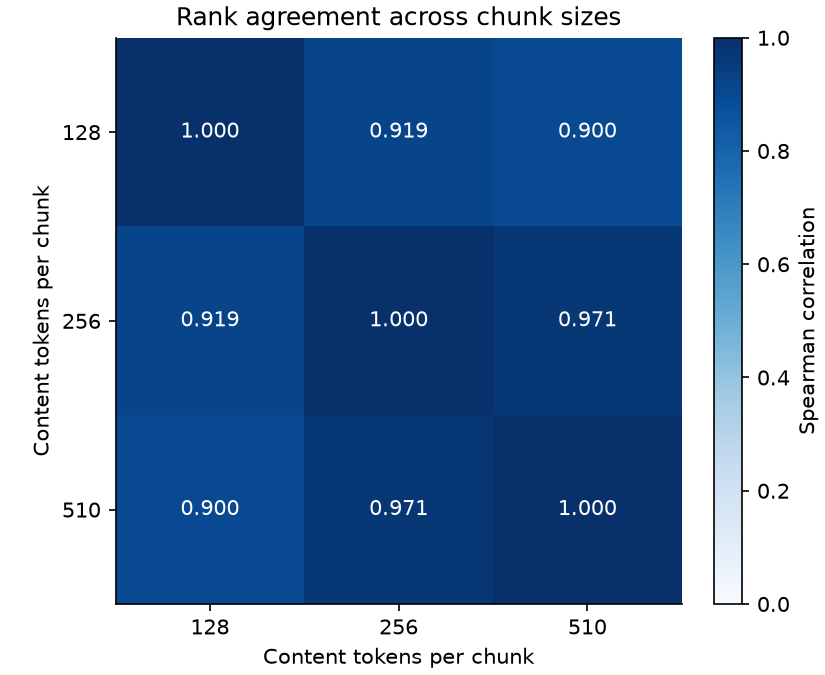

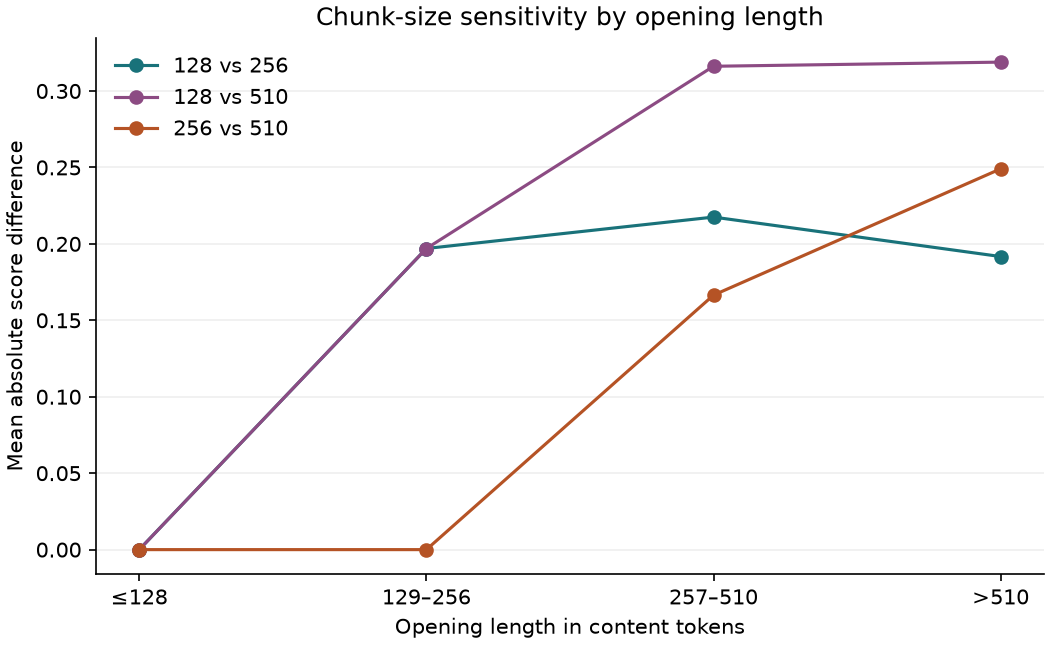

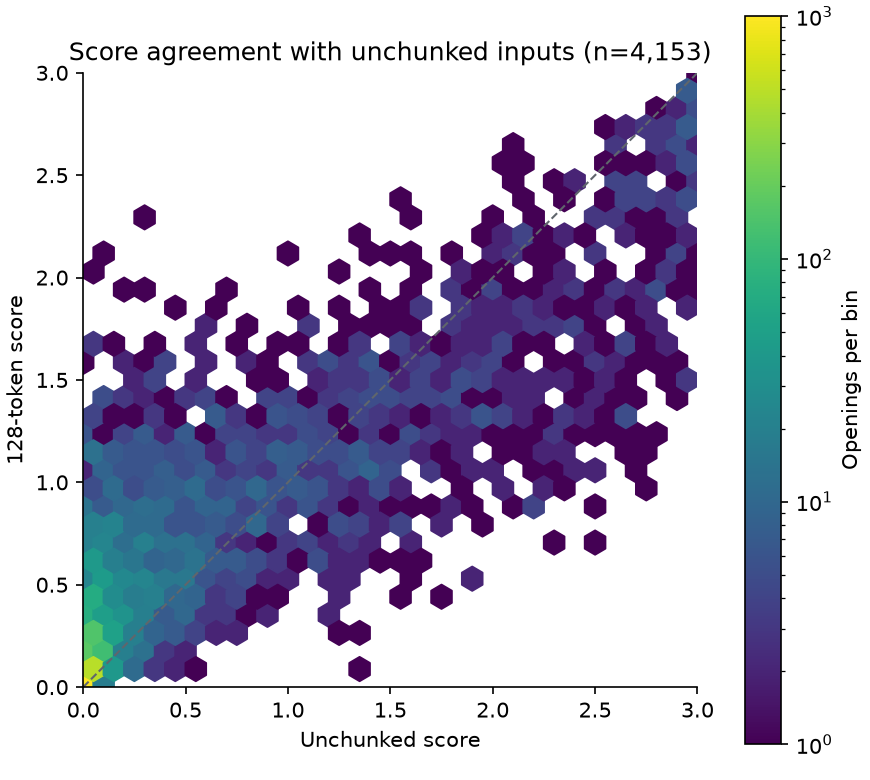

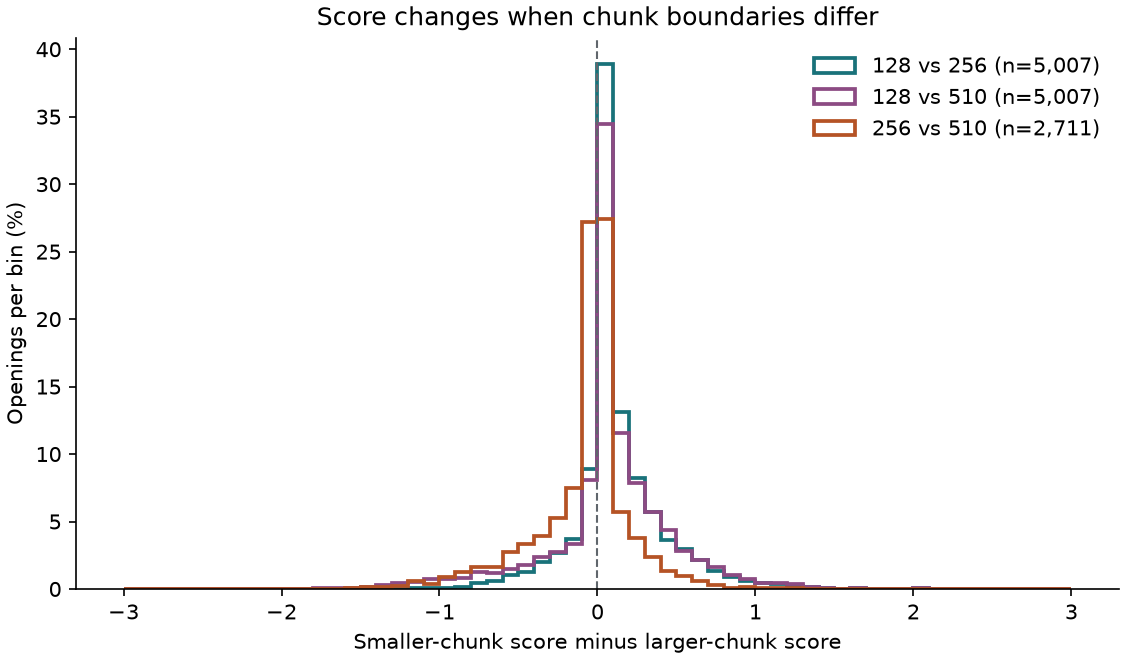

In [4]:
from IPython.display import Image, display

chart_labels = {
    "correlation_heatmap.png": "Spearman rank correlation between the three chunk sizes",
    "sensitivity_by_length.png": "Average absolute change in score by opening length",
    "score_agreement.png": "Agreement between the 128-token and unchunked scores",
    "score_difference_distribution.png": "Distribution of signed score changes among openings with different segmentations"
}
for filename, label in chart_labels.items():
    display(Image(filename=str(phase2_analysis / filename), alt=label))


### What Phase 2 found

**Wider chunks tracked the unchunked reference more closely.** Across the same 5,727 openings that fit in one 510-token window, the 256-token configuration had a mean absolute difference of 0.054 points on the 0–3 scale, compared with 0.182 at 128 tokens. The Spearman correlations were 0.976 and 0.899, and class agreement was 98.3% and 94.7%, respectively. These figures include openings with identical inputs. In the 257–510-token band, where both smaller configurations changed the boundaries, the mean absolute differences were 0.167 at 256 and 0.316 at 128.

**Longer openings were more sensitive.** Comparing 128 with 510 tokens, the mean absolute difference rose from 0.197 in the 129–256-token band to 0.316 in the 257–510-token band. Among the 854 openings above 510 tokens, where the reference itself uses multiple chunks, class agreement was 89.2% for 128 vs. 510 and 89.5% for 256 vs. 510.

**The subgroup patterns are descriptive.** In the 257–510-token band, the 128-vs.-510 average difference ranged from 0.259 in Ethics & religion to 0.419 in Technology & environment. Winners showed somewhat larger differences than comparison openings across the three bands above 128 tokens. For example, the 257–510-token averages were 0.331 and 0.296. Length and other differences within the bands can contribute to these gaps.

Scoring took 18.8 minutes on CPU. The shared cache avoided 7,253 of 36,312 chunk evaluations. These results establish sensitivity to chunk size and help prioritize the boundary robustness and human validation phases. Agreement with the unchunked model measures consistency, while agreement with human judgments remains open.

### Reproduce Phase 2

From the project root in the project environment, use the same checkpoint as Phase 1.

```sh
python project/notebooks/linguistic-features/politeness_experiment/run_chunk_size_experiment.py
python project/notebooks/linguistic-features/politeness_experiment/analyze_chunk_sizes.py
```

The run directory holds the argument scores, chunk probabilities, and experiment metadata. Its analysis directory holds both agreement tables and the four figures. Reported timings are for successive configurations with a shared cache.

## Phase 3 robustness to randomized boundaries at 256 tokens

This run uses 1,000 distinct training openings. It includes all 854 openings above 510 tokens and a seeded sample of 146 openings drawn across length quartiles within the 257–510-token range. The reference for each opening is its fixed-boundary **256-token** score from Phase 2.

The sampler keeps the content tokens, their order, the 256-token limit, and the original chunk count fixed. For each opening, it allocates the unused chunk capacity across chunks and draws up to five distinct layouts, excluding the fixed layout. Each token appears exactly once. The fixed layout fills the earliest chunks, so perturbations can only move internal boundaries earlier. The unused capacity is the maximum possible shift. The output records chunk lengths, individual boundary displacements, and the number of available and sampled layouts.

### Opening-level stability

For each opening, we average the absolute and signed score changes from its fixed-boundary reference and calculate trial-to-trial standard deviation and class agreement. The overall summary gives each opening equal weight. An opening needs at least one valid change to contribute and at least two layouts for its trial standard deviation. Rank correlation is shown separately by trial and between the fixed score and each opening's mean randomized score.

In [5]:
phase3_run_id = "20261124T053603636041Z-256-only"
phase3_run = project / "data/processed/linguistic-features/politeness-experiment/phase-3" / phase3_run_id
phase3_analysis = phase3_run / "analysis"
phase3_manifest = json.loads((phase3_run / "experiment_metadata.json").read_text())
assert phase3_manifest["phase"] == 3 and phase3_manifest["split"] == "train"
assert [configuration["content_limit"] for configuration in phase3_manifest["configurations"]] == [256]

def phase3_table(name):
    return pd.read_csv(phase3_analysis / f"{name}.csv")

argument_summary = phase3_table("argument_summary")
print(argument_summary.drop(columns="content_limit").T.round(4).to_string(header=False))
print()
print("By training opening length")
fields = ["length_band", "n_perturbable", "mean_displacement", "mean_absolute_change", "class_agreement"]
print(phase3_table("argument_by_length")[fields].round(4).to_string(index=False))
print()
print("Ranks by trial")
print(phase3_table("rank_by_trial").drop(columns="content_limit").round(4).to_string(index=False))


n_openings                   1000.0000
n_perturbable                 996.0000
n_fewer_than_five_layouts      11.0000
at_most_one_token              11.0000
mean_absolute_change            0.1740
mean_signed_change             -0.0098
mean_trial_score_sd             0.1393
class_agreement                 0.9464
spearman_against_mean           0.9325
mean_displacement              76.7433
mean_available_displacement   152.6928
mean_fraction_displaced         0.5061

By training opening length
length_band  n_perturbable  mean_displacement  mean_absolute_change  class_agreement
    257–384             96           100.5479                0.2038           0.8792
    385–510             50            41.0520                0.1257           0.9920
    511–768            537            76.7818                0.1772           0.9460
  769–1,020            182            76.2300                0.1739           0.9516
     >1,020            131            73.4761                0.1576           0

### Matched-pair stability

Each of the five trials retains all 3,451 matched pairs, scored in the original A-minus-B orientation. Each side uses its randomized score if a layout is available in that trial and its Phase 2 score otherwise. Differences within 1e-9 count as ties. A reversal switches from positive to negative or vice versa. Changes into and out of ties are recorded separately. Rates use the indicated number of pair-trials per exposure group.

In [6]:
pair_summary = phase3_table("pair_summary").drop(columns=["cohort", "content_limit"])
print(pair_summary.round(4).to_string(index=False))


 randomized_openings  n_pair_trials  n_unique_pairs  mean_absolute_difference_change  ranking_agreement  rank_reversal_rate  into_tie_rate  out_of_tie_rate
                   0          12943            2590                           0.0000             1.0000              0.0000            0.0           0.0000
                   1           3470             699                           0.1718             0.9343              0.0657            0.0           0.0000
                   2            842             170                           0.2724             0.8575              0.1366            0.0           0.0059


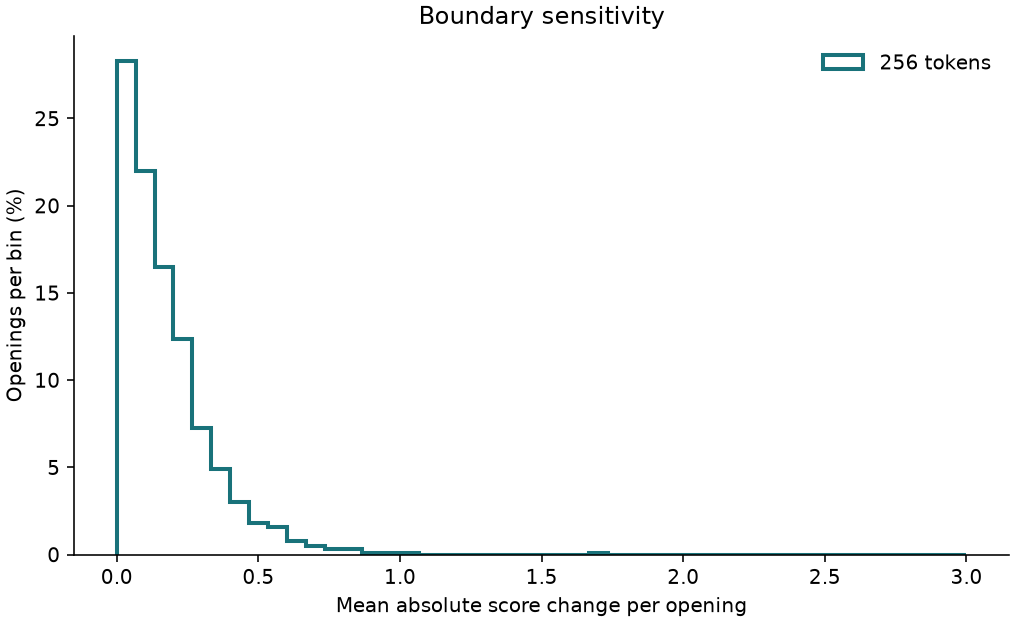

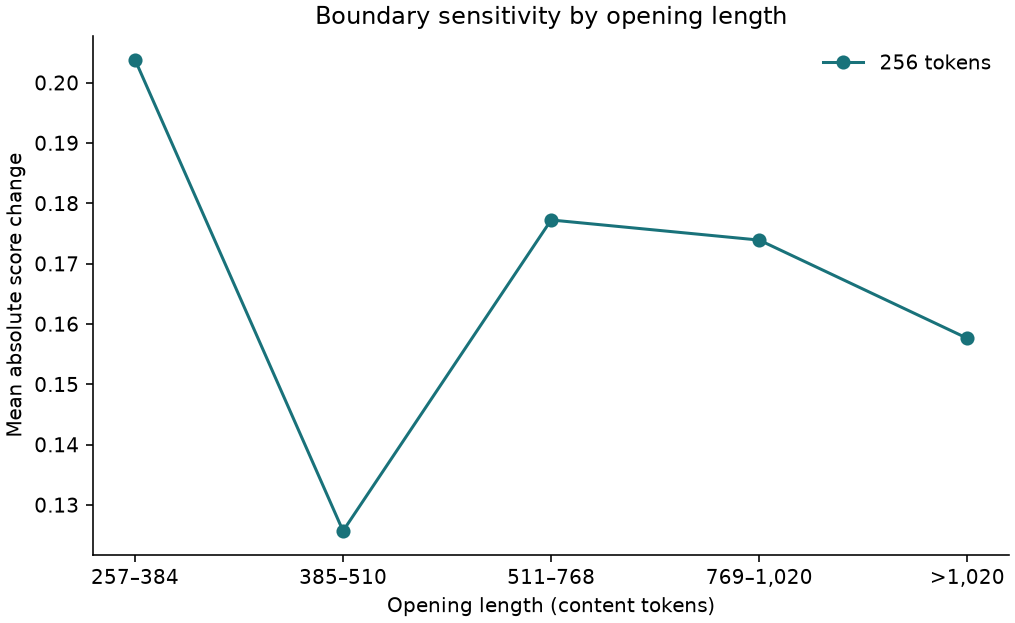

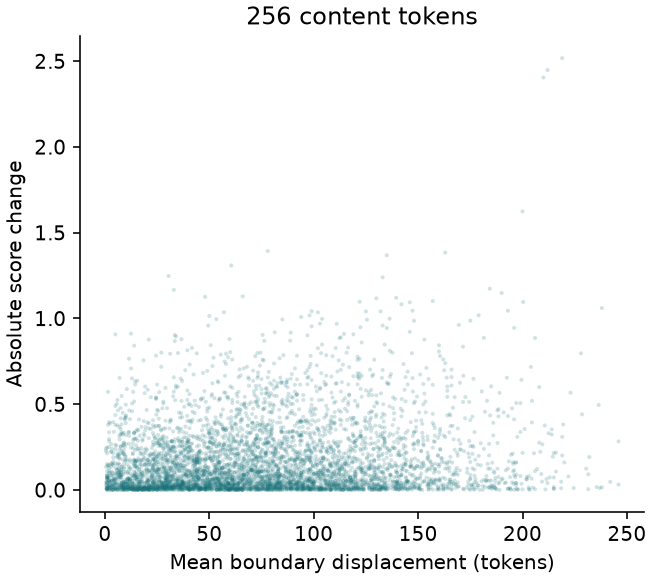

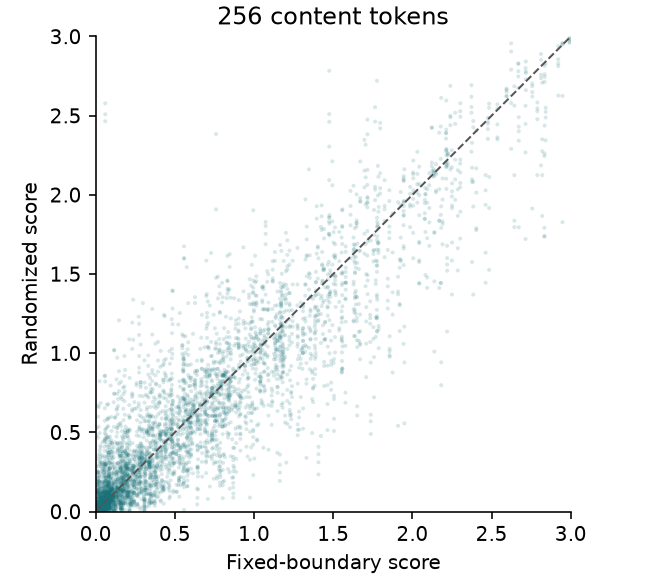

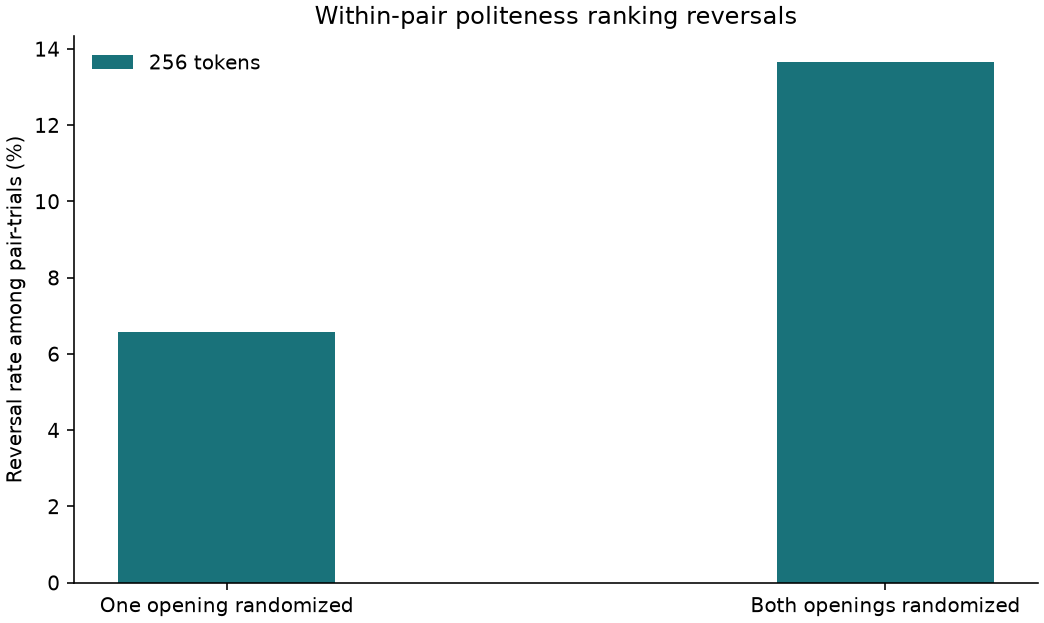

In [7]:
from IPython.display import Image, display

phase3_chart_labels = {
    "absolute_score_changes.png": "Distribution of mean absolute score changes across training openings",
    "sensitivity_by_length.png": "Average absolute score change by opening length",
    "score_change_vs_displacement.png": "Absolute score change against the realized boundary displacement",
    "fixed_vs_randomized.png": "Fixed-boundary scores versus scores with randomized boundaries",
    "paired_ranking_reversals.png": "Pair-trial reversal rates when one or both openings were randomized"
}
for filename, label in phase3_chart_labels.items():
    display(Image(filename=str(phase3_analysis / filename), alt=label))


### What Phase 3 found at 256 tokens

- **The score moved under boundary changes.** Across 996 perturbable openings, the mean absolute change was 0.174 points on the 0–3 scale. The mean signed change was −0.010 and mean class agreement was 94.6%. The median opening-level absolute change was 0.133, and the 90th percentile was 0.380. Individual trial rank correlations ranged from 0.894 to 0.907.
- **Flexibility varied by opening.** Four openings allowed zero alternatives, six allowed one, and one allowed two. The remaining 989 contributed five distinct layouts. The 257–384-token band had the largest average change (0.204) and the largest average shift (about 101 tokens). The 385–510-token band averaged 0.126 points and about 41 tokens of shift. The observed differences across length bands also reflect how far boundaries could move.
- **Relative politeness can flip within a pair.** Rankings reversed in 228 of 3,470 pair-trials (6.6%) with one side perturbed and 115 of 842 (13.7%) with both sides perturbed. Five trials with both sides perturbed moved out of a tie, and none moved into a tie. This variation can affect the paired politeness feature used in a later predictive model.

These results describe the 256-token configuration on training openings. Human validation will assess whether the scores reflect perceived politeness.

### Reproduce the 256-token experiment

Run from the project root in the same CPU environment used for Phase 2. The first command scores the randomized layouts and writes a timestamped directory. The second reads the most recent Phase 3 run and writes agreement tables, opening and pair records, and five figures.

```sh
python project/notebooks/linguistic-features/politeness_experiment/run_boundary_experiment.py --content-limits 256
python project/notebooks/linguistic-features/politeness_experiment/analyze_boundaries.py
```

[Scoring runner](run_boundary_experiment.py) · [Analysis and figures](analyze_boundaries.py)